# Notebook 06 — Optuna & MLflow
## Projet : Plateforme AutoML & MLOps — Telco Customer Churn

**Objectif :** poursuivre les notebooks 01 à 05 en optimisant le SVM avec Optuna et en traçant les expériences avec MLflow.

Ce notebook ne refait ni l'EDA ni le preprocessing. Il charge directement les fichiers prétraités produits par le Notebook 02 et conserve le SVM existant comme baseline.

### Règles méthodologiques
- Optuna et la validation croisée utilisent uniquement `X_train` et `y_train`.
- `X_test` et `y_test` ne sont utilisés qu'après la fin de l'optimisation.
- Le choix de la version à enregistrer dans le Model Registry se base sur le **F1 CV (train)**, pas sur le score du jeu de test.
- Les performances Test servent à l'évaluation finale et à l'interprétation métier.
- Le SVM original est conservé ; le nouveau modèle est écrit dans un fichier distinct.

In [29]:
# Installation des dépendances dans le kernel Jupyter courant.
%pip install -q "optuna>=3.5" "mlflow>=2.9" scikit-learn pandas numpy matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


> **Important :** après la cellule d'installation, si Jupyter affiche *“you may need to restart the kernel to use updated packages”*, choisissez **Kernel → Restart Kernel**, puis relancez les cellules depuis le début. Cette notification n'est pas une erreur.

In [30]:
import os
import sys
import json
import warnings
import platform
from pathlib import Path

import joblib
import mlflow
import mlflow.sklearn
import numpy as np
import optuna
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from mlflow.tracking import MlflowClient
from sklearn.base import clone
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc,
)

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
N_TRIALS = 10
N_SPLITS = 3
POSITIVE_LABEL = 1

print("Python :", sys.version.split()[0])
print("Plateforme :", platform.platform())
print("Scikit-learn :", sklearn.__version__)
print("Optuna :", optuna.__version__)
print("MLflow :", mlflow.__version__)

Python : 3.12.0
Plateforme : Windows-11-10.0.26200-SP0
Scikit-learn : 1.9.1
Optuna : 5.0.0
MLflow : 3.18.0


## 1. Configuration et détection du projet

Le notebook est prévu pour être placé dans `notebooks/`. Le dossier racine est déterminé automatiquement en recherchant `data/processed/` dans le dossier courant et ses parents.

Une variable d'environnement `AUTOML_PROJECT_DIR` peut être utilisée pour indiquer explicitement le projet. Chaque chemin est vérifié avant utilisation.

In [31]:
# Détection du répertoire racine.
cwd = Path.cwd().resolve()
candidate_roots = []

project_override = os.environ.get("AUTOML_PROJECT_DIR")
if project_override:
    candidate_roots.append(Path(project_override).expanduser().resolve())

candidate_roots.extend([cwd, *cwd.parents])

# Chemin du projet communiqué dans le cahier des charges (fallback, vérifié).
windows_project_path = Path(r"C:\Users\Octinz\Documents\automl-mlops-platform")
candidate_roots.append(windows_project_path)

# Supprimer les doublons tout en conservant l'ordre.
unique_roots = []
seen_roots = set()
for candidate in candidate_roots:
    key = str(candidate).lower()
    if key not in seen_roots:
        unique_roots.append(candidate)
        seen_roots.add(key)

PROJECT_DIR = next(
    (
        root for root in unique_roots
        if root.is_dir() and (root / "data" / "processed").is_dir()
    ),
    None,
)

if PROJECT_DIR is None:
    searched = "\n".join(f"- {p}" for p in unique_roots)
    raise FileNotFoundError(
        "Impossible de détecter la racine du projet. "
        "Le dossier data/processed/ doit exister.\n"
        f"Dossiers vérifiés :\n{searched}\n"
        "Astuce : définissez AUTOML_PROJECT_DIR vers la racine du projet."
    )

DATA_DIR = PROJECT_DIR / "data" / "processed"
MODELS_DIR = PROJECT_DIR / "models"
REPORTS_DIR = PROJECT_DIR / "reports"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

REQUIRED_DATA_FILES = [
    DATA_DIR / "X_train_processed.csv",
    DATA_DIR / "X_test_processed.csv",
    DATA_DIR / "y_train.csv",
    DATA_DIR / "y_test.csv",
]

missing_files = [path for path in REQUIRED_DATA_FILES if not path.is_file()]
if missing_files:
    raise FileNotFoundError(
        "Fichiers de données manquants :\n" +
        "\n".join(f"- {p}" for p in missing_files)
    )

print("PROJECT_DIR :", PROJECT_DIR)
print("DATA_DIR    :", DATA_DIR)
print("MODELS_DIR  :", MODELS_DIR)
print("REPORTS_DIR :", REPORTS_DIR)

PROJECT_DIR : C:\Users\Octinz\Documents\automl-mlops-platform
DATA_DIR    : C:\Users\Octinz\Documents\automl-mlops-platform\data\processed
MODELS_DIR  : C:\Users\Octinz\Documents\automl-mlops-platform\models
REPORTS_DIR : C:\Users\Octinz\Documents\automl-mlops-platform\reports


## 2. Chargement des données prétraitées et du SVM original

Le modèle original est chargé comme baseline. Le notebook ne modifie ni ce fichier, ni les autres modèles déjà présents dans `models/`.

In [32]:
X_train = pd.read_csv(DATA_DIR / "X_train_processed.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_processed.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze("columns")
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze("columns")

y_train = pd.to_numeric(y_train, errors="raise").astype(int)
y_test = pd.to_numeric(y_test, errors="raise").astype(int)

baseline_candidates = [
    MODELS_DIR / "best_model_evaluated.joblib",
    MODELS_DIR / "best_model.joblib",
    PROJECT_DIR / "best_model_evaluated.joblib",
    PROJECT_DIR / "best_model.joblib",
]

baseline_path = next((p for p in baseline_candidates if p.is_file()), None)
if baseline_path is None:
    raise FileNotFoundError(
        "SVM original introuvable. Fichier attendu : "
        "models/best_model_evaluated.joblib ou models/best_model.joblib."
    )

# Charger uniquement un artefact de modèle de confiance provenant de ce projet.
baseline_model = joblib.load(baseline_path)

if not hasattr(baseline_model, "predict") or not hasattr(baseline_model, "get_params"):
    raise TypeError(
        f"Le fichier chargé ({type(baseline_model).__name__}) n'est pas un estimateur scikit-learn compatible."
    )

print("Modèle baseline :", baseline_path)
print("Type du modèle :", type(baseline_model).__name__)
print("Dimensions :")
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

Modèle baseline : C:\Users\Octinz\Documents\automl-mlops-platform\models\best_model_evaluated.joblib
Type du modèle : SVC
Dimensions :
X_train : (5634, 45)
X_test  : (1409, 45)
y_train : (5634,)
y_test  : (1409,)


In [33]:
# Vérifications de cohérence avant tout entraînement.
assert len(X_train) == len(y_train), "X_train et y_train ont des tailles différentes."
assert len(X_test) == len(y_test), "X_test et y_test ont des tailles différentes."
assert list(X_train.columns) == list(X_test.columns), "Les colonnes Train et Test ne correspondent pas."
assert X_train.columns.is_unique, "Les noms de colonnes de X_train ne sont pas uniques."
assert X_train.isna().sum().sum() == 0, "X_train contient des valeurs manquantes."
assert X_test.isna().sum().sum() == 0, "X_test contient des valeurs manquantes."
assert all(pd.api.types.is_numeric_dtype(t) for t in X_train.dtypes), (
    "Les features doivent être numériques : vérifiez le preprocessing du Notebook 02."
)
assert set(y_train.unique()).issubset({0, 1}), "La cible train doit être encodée en 0/1."
assert set(y_test.unique()).issubset({0, 1}), "La cible test doit être encodée en 0/1."
assert y_train.nunique() == 2 and y_test.nunique() == 2, "Les deux classes doivent être présentes."
assert X_train.shape[1] == X_test.shape[1], "Le nombre de features est différent."

if hasattr(baseline_model, "n_features_in_"):
    assert baseline_model.n_features_in_ == X_train.shape[1], (
        "Le nombre de features attendu par le SVM baseline ne correspond pas aux données."
    )

print("Validation terminée : dimensions, colonnes, types et cible sont cohérents.")
print("\nDistribution de la cible Train :")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())

Validation terminée : dimensions, colonnes, types et cible sont cohérents.

Distribution de la cible Train :


,Proportion
Churn,
0,0.734647
1,0.265353


## 3. Configuration de MLflow Tracking

MLflow Tracking conserve les paramètres, métriques, artefacts et modèles associés à chaque exécution.

Pour utiliser également le **Model Registry** en local, ce notebook configure un backend de tracking basé sur **SQLite** (`mlflow.db`). Le stockage des artefacts est un dossier local `mlartifacts/` dans le projet. Cette configuration évite de dépendre du backend `file://` historique, qui n'est pas adapté au Model Registry dans certaines versions de MLflow.

In [34]:
MLFLOW_DB_PATH = PROJECT_DIR / "mlflow.db"
MLFLOW_ARTIFACTS_DIR = PROJECT_DIR / "mlartifacts"
MLFLOW_ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# as_posix() produit des séparateurs compatibles avec les URI SQLite sous Windows.
TRACKING_URI = "sqlite:///" + MLFLOW_DB_PATH.resolve().as_posix()
EXPERIMENT_NAME = "Telco_Churn_AutoML"
REGISTRY_MODEL_NAME = "TelcoChurnClassifier"

mlflow.set_tracking_uri(TRACKING_URI)
mlflow.set_registry_uri(TRACKING_URI)

client = MlflowClient()

experiment = client.get_experiment_by_name(EXPERIMENT_NAME)
if experiment is None:
    artifact_location = (MLFLOW_ARTIFACTS_DIR / EXPERIMENT_NAME).resolve().as_uri()
    experiment_id = client.create_experiment(
        name=EXPERIMENT_NAME,
        artifact_location=artifact_location,
    )
else:
    experiment_id = experiment.experiment_id

mlflow.set_experiment(EXPERIMENT_NAME)

print("Tracking URI :", mlflow.get_tracking_uri())
print("Registry URI :", mlflow.get_registry_uri())
print("Experiment   :", EXPERIMENT_NAME)
print("Experiment ID:", experiment_id)
print("Artefacts    :", MLFLOW_ARTIFACTS_DIR)

Tracking URI : sqlite:///C:/Users/Octinz/Documents/automl-mlops-platform/mlflow.db
Registry URI : sqlite:///C:/Users/Octinz/Documents/automl-mlops-platform/mlflow.db
Experiment   : Telco_Churn_AutoML
Experiment ID: 1
Artefacts    : C:\Users\Octinz\Documents\automl-mlops-platform\mlartifacts


### Tracking et Registry : quelle différence ?

- **Experiment Tracking** : journalise les expériences (paramètres, scores, versions de code/données renseignées, fichiers et modèles). Il permet de comparer les essais.
- **Model Registry** : conserve les versions nommées d'un modèle sélectionné, par exemple `TelcoChurnClassifier`, et permet de retrouver la version, son run source et ses artefacts.

Le tracking répond à *« qu'a-t-on essayé et avec quels résultats ? »* ; le registry répond à *« quelles versions du modèle sont enregistrées et prêtes à être gérées ? »*.

## 4. Préparation de la validation croisée

Nous utilisons `StratifiedKFold` avec 3 folds pour conserver la proportion de chaque classe dans les folds et limiter le coût sur un PC personnel.

Le score d'optimisation est le **F1-score de la classe Churn (1)**. La même configuration de folds est utilisée pour le baseline et Optuna afin de rendre leurs scores CV comparables.

In [35]:
cv_strategy = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

print(f"Validation croisée : {N_SPLITS} folds stratifiés")
print(f"Nombre de trials Optuna : {N_TRIALS}")
print("Métrique d'optimisation : F1-score (positive label = 1)")

Validation croisée : 3 folds stratifiés
Nombre de trials Optuna : 10
Métrique d'optimisation : F1-score (positive label = 1)


## 5. Optimisation du SVM avec Optuna

Optuna explore :
- `C` sur une échelle logarithmique ;
- `kernel` parmi `linear` et `rbf` ;
- `gamma` uniquement lorsque `kernel='rbf'` ; pour `linear`, la valeur reste `scale` (ignorée par ce noyau) ;
- `class_weight` parmi aucune pondération et `balanced`.

Chaque trial est exécuté dans un **run MLflow enfant** contenant ses paramètres et son F1 CV moyen/écart-type. Un run parent regroupe l'étude entière.

In [36]:
def build_svm_from_trial(trial):
    """Construit un SVC à partir des paramètres proposés par Optuna."""
    C = trial.suggest_float("C", 1e-2, 1e2, log=True)
    kernel = trial.suggest_categorical("kernel", ["linear", "rbf"])
    class_weight_choice = trial.suggest_categorical(
        "class_weight", ["none", "balanced"]
    )
    class_weight = None if class_weight_choice == "none" else "balanced"

    if kernel == "rbf":
        gamma = trial.suggest_float("gamma", 1e-4, 1.0, log=True)
    else:
        # gamma n'intervient pas pour le noyau linéaire.
        gamma = "scale"

    model = SVC(
        C=C,
        kernel=kernel,
        gamma=gamma,
        class_weight=class_weight,
        probability=False,
        random_state=RANDOM_STATE,
        cache_size=256,
    )
    return model, {
        "C": C,
        "kernel": kernel,
        "gamma": gamma,
        "class_weight": class_weight_choice,
    }


def objective(trial):
    model, trial_params = build_svm_from_trial(trial)

    with mlflow.start_run(
        run_name=f"Optuna_Trial_{trial.number:03d}",
        nested=True,
    ) as trial_run:
        mlflow.set_tags({
            "stage": "optuna_trial",
            "model_family": "SVM",
            "optuna_trial_number": str(trial.number),
        })
        mlflow.log_params({
            "trial_number": trial.number,
            **{key: str(value) for key, value in trial_params.items()},
            "cv_n_splits": N_SPLITS,
            "scoring": "f1",
        })

        fold_scores = cross_val_score(
            estimator=model,
            X=X_train,
            y=y_train,
            scoring="f1",
            cv=cv_strategy,
            n_jobs=1,  # éviter la multiplication des processus sur un PC personnel
            error_score="raise",
        )

        mean_f1 = float(np.mean(fold_scores))
        std_f1 = float(np.std(fold_scores))

        mlflow.log_metrics({
            "f1_cv_mean": mean_f1,
            "f1_cv_std": std_f1,
        })

        trial.set_user_attr("f1_cv_std", std_f1)
        trial.set_user_attr("mlflow_run_id", trial_run.info.run_id)

    return mean_f1


sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(
    study_name="Telco_Churn_SVM_Optuna",
    direction="maximize",
    sampler=sampler,
)

with mlflow.start_run(run_name="SVM_Optuna_Study") as optimization_run:
    mlflow.set_tags({
        "stage": "hyperparameter_optimization",
        "model_family": "SVM",
        "dataset": "Telco Customer Churn",
    })
    mlflow.log_params({
        "n_trials": N_TRIALS,
        "cv_n_splits": N_SPLITS,
        "cv_strategy": "StratifiedKFold",
        "optimization_metric": "f1",
        "random_state": RANDOM_STATE,
    })

    study.optimize(
        objective,
        n_trials=N_TRIALS,
        n_jobs=1,
        show_progress_bar=True,
    )

    mlflow.log_metric("best_cv_f1", float(study.best_value))
    mlflow.log_params({
        f"best_{key}": str(value)
        for key, value in study.best_params.items()
    })

OPTUNA_STUDY_RUN_ID = optimization_run.info.run_id

print("Optimisation terminée.")
print("Run parent MLflow :", OPTUNA_STUDY_RUN_ID)

[I 2026-11-14 12:58:50,895] A new study created in memory with name: Telco_Churn_SVM_Optuna


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-14 12:58:54,712] Trial 0 finished with value: 0.5837073133394276 and parameters: {'C': 0.31489116479568624, 'kernel': 'linear', 'class_weight': 'none'}. Best is trial 0 with value: 0.5837073133394276.
[I 2026-11-14 12:59:04,793] Trial 1 finished with value: 0.13995232085261536 and parameters: {'C': 0.042070539502879395, 'kernel': 'rbf', 'class_weight': 'balanced', 'gamma': 0.00012087541473056971}. Best is trial 0 with value: 0.5837073133394276.
[I 2026-11-14 13:08:45,406] Trial 2 finished with value: 0.5983830912492719 and parameters: {'C': 75.7947995334801, 'kernel': 'linear', 'class_weight': 'balanced'}. Best is trial 2 with value: 0.5983830912492719.
[I 2026-11-14 13:08:48,812] Trial 3 finished with value: 0.5983830912492719 and parameters: {'C': 0.1648044642797898, 'kernel': 'linear', 'class_weight': 'balanced'}. Best is trial 2 with value: 0.5983830912492719.
[I 2026-11-14 13:08:58,775] Trial 4 finished with value: 0.13995232085261536 and parameters: {'C': 0.03613894271

In [37]:
print("Meilleur trial :", study.best_trial.number)
print("Meilleur F1 CV :", round(float(study.best_value), 5))
print("Meilleurs hyperparamètres :")
display(pd.DataFrame(
    [{"Paramètre": key, "Valeur": value} for key, value in study.best_params.items()]
))

Meilleur trial : 8
Meilleur F1 CV : 0.61865
Meilleurs hyperparamètres :


,Paramètre,Valeur
0,C,43.379207
1,kernel,rbf
2,class_weight,balanced
3,gamma,0.015376


## 6. Historique des trials et sauvegarde des résultats Optuna

Le graphique montre le F1 CV de chaque trial et le meilleur score cumulatif atteint. Les résultats sont exportés dans `reports/optuna_trials.csv` et `reports/optuna_best_params.json`.

In [38]:
trial_records = []
for optuna_trial in study.trials:
    record = {
        "trial": optuna_trial.number,
        "state": optuna_trial.state.name,
        "f1_cv": optuna_trial.value,
        "duration_seconds": (
            optuna_trial.duration.total_seconds()
            if optuna_trial.duration is not None else np.nan
        ),
        "mlflow_run_id": optuna_trial.user_attrs.get("mlflow_run_id"),
    }
    for key, value in optuna_trial.params.items():
        record[f"param_{key}"] = value
    trial_records.append(record)

optuna_trials_df = pd.DataFrame(trial_records)
display(optuna_trials_df)

trials_path = REPORTS_DIR / "optuna_trials.csv"
best_params_path = REPORTS_DIR / "optuna_best_params.json"

optuna_trials_df.to_csv(trials_path, index=False)

best_params_for_json = dict(study.best_params)
best_params_for_json["gamma"] = (
    study.best_params["gamma"] if "gamma" in study.best_params else "scale"
)
best_params_for_json["class_weight_sklearn"] = (
    None if study.best_params["class_weight"] == "none" else "balanced"
)

with open(best_params_path, "w", encoding="utf-8") as file:
    json.dump(
        {
            "best_trial": int(study.best_trial.number),
            "best_cv_f1": float(study.best_value),
            "best_params": best_params_for_json,
        },
        file,
        ensure_ascii=False,
        indent=4,
    )

print("Fichiers sauvegardés :", trials_path, "et", best_params_path)

,trial,state,f1_cv,duration_seconds,mlflow_run_id,param_C,param_kernel,param_class_weight,param_gamma
0,0,COMPLETE,0.583707,3.721766,2bb18e129040484e90e622245a17e9e1,0.314891,linear,none,NaN
1,1,COMPLETE,0.139952,10.075337,81e7544f66184ec3b1401b2a612161e8,0.042071,rbf,balanced,0.000121
2,2,COMPLETE,0.598383,580.609781,c364fc4e5bf44b7aa8ac95fc9794231a,75.794800,linear,balanced,NaN
3,3,COMPLETE,0.598383,3.399845,ffee8888d18b484b9dd9caeaa9b7a7b1,0.164804,linear,balanced,NaN
4,4,COMPLETE,0.139952,9.959581,beed31fa04414d8c95fef078d0bff374,0.036139,rbf,balanced,0.000629
5,5,COMPLETE,0.585787,4.064573,9d90a15bb55b4b77991fafda4c37a87a,1.140086,linear,none,NaN
6,6,COMPLETE,0.000000,4.584686,a38128f0408b4bed80e398cbf8e02f6b,0.018206,rbf,none,0.000246
7,7,COMPLETE,0.586411,6.580394,3304ae1d6e6842d3b9a05b2b53046ed8,5.456725,linear,none,NaN
8,8,COMPLETE,0.618648,7.055187,debde649bf2649c88e3388310c32b4da,43.379207,rbf,balanced,0.015376
9,9,COMPLETE,0.583506,2.755289,377e123a6ffe48fa803ec61e07e0339e,0.054880,linear,none,NaN


Fichiers sauvegardés : C:\Users\Octinz\Documents\automl-mlops-platform\reports\optuna_trials.csv et C:\Users\Octinz\Documents\automl-mlops-platform\reports\optuna_best_params.json


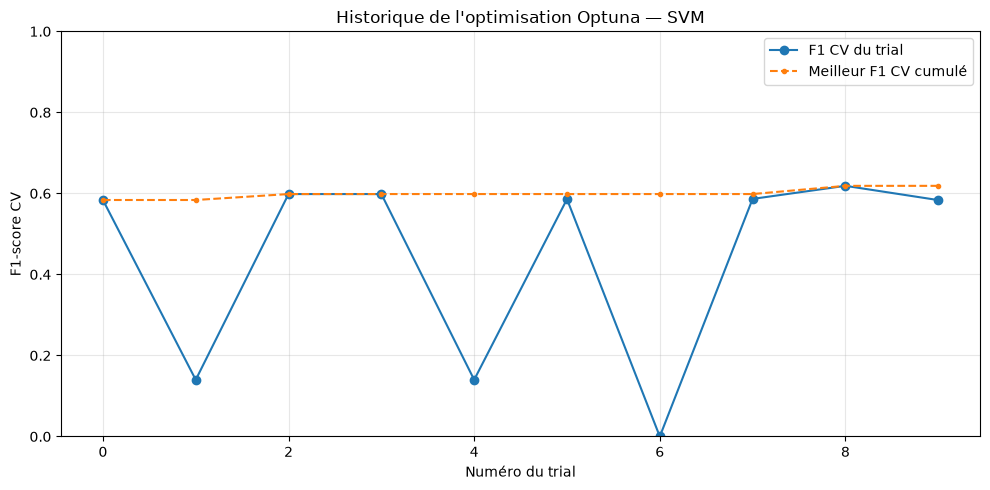

In [39]:
valid_trials = optuna_trials_df.dropna(subset=["f1_cv"]).sort_values("trial")
if valid_trials.empty:
    raise RuntimeError("Aucun trial Optuna valide : consultez les erreurs affichées plus haut.")

valid_trials = valid_trials.copy()
valid_trials["best_so_far"] = valid_trials["f1_cv"].cummax()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(valid_trials["trial"], valid_trials["f1_cv"], marker="o", label="F1 CV du trial")
ax.plot(valid_trials["trial"], valid_trials["best_so_far"], marker=".", linestyle="--", label="Meilleur F1 CV cumulé")
ax.set_title("Historique de l'optimisation Optuna — SVM")
ax.set_xlabel("Numéro du trial")
ax.set_ylabel("F1-score CV")
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
optuna_history_path = REPORTS_DIR / "optuna_optimization_history.png"
plt.savefig(optuna_history_path, dpi=150, bbox_inches="tight")
plt.show()

## 7. Entraînement du SVM optimisé sur tout le jeu Train

Les meilleurs paramètres sont réutilisés pour créer un nouveau SVM, ensuite entraîné sur `X_train` et `y_train` complets. Le baseline n'est pas écrasé.

Le nouveau fichier sera `models/svm_optuna_model.joblib`.

In [40]:
best_optuna_params = dict(study.best_params)
best_class_weight = (
    None if best_optuna_params["class_weight"] == "none" else "balanced"
)
best_gamma = best_optuna_params.get("gamma", "scale")

optuna_model = SVC(
    C=float(best_optuna_params["C"]),
    kernel=best_optuna_params["kernel"],
    gamma=best_gamma,
    class_weight=best_class_weight,
    probability=False,
    random_state=RANDOM_STATE,
    cache_size=256,
)

optuna_model.fit(X_train, y_train)

OPTUNA_MODEL_PATH = MODELS_DIR / "svm_optuna_model.joblib"
joblib.dump(optuna_model, OPTUNA_MODEL_PATH)

print("SVM Optuna entraîné sur l'ensemble du jeu Train.")
print("Modèle sauvegardé :", OPTUNA_MODEL_PATH)
print("Taille du fichier :", f"{OPTUNA_MODEL_PATH.stat().st_size:,}", "octets")

SVM Optuna entraîné sur l'ensemble du jeu Train.
Modèle sauvegardé : C:\Users\Octinz\Documents\automl-mlops-platform\models\svm_optuna_model.joblib
Taille du fichier : 1,116,955 octets


## 8. Score CV du baseline

Pour comparer équitablement le SVM original avec Optuna, le baseline est évalué avec le même `StratifiedKFold` et le même F1-score sur les seules données Train.

`cross_val_score` clone et réentraîne l'estimateur dans chaque fold ; le modèle baseline sauvegardé reste inchangé. Si le SVM original a `probability=True`, cette option est désactivée uniquement pour cette mesure CV afin de réduire le temps de calcul (elle n'est pas nécessaire au F1).

In [41]:
baseline_cv_estimator = clone(baseline_model)
if "probability" in baseline_cv_estimator.get_params(deep=False):
    baseline_cv_estimator.set_params(probability=False)

baseline_cv_scores = cross_val_score(
    estimator=baseline_cv_estimator,
    X=X_train,
    y=y_train,
    scoring="f1",
    cv=cv_strategy,
    n_jobs=1,
    error_score="raise",
)
baseline_cv_f1 = float(np.mean(baseline_cv_scores))
baseline_cv_std = float(np.std(baseline_cv_scores))

print("Baseline F1 CV moyen :", round(baseline_cv_f1, 5))
print("Baseline F1 CV écart-type :", round(baseline_cv_std, 5))
print("Optuna F1 CV moyen :", round(float(study.best_value), 5))

Baseline F1 CV moyen : 0.62133
Baseline F1 CV écart-type : 0.01462
Optuna F1 CV moyen : 0.61865


## 9. Évaluation finale sur le jeu Test

L'optimisation et le choix des hyperparamètres sont maintenant terminés. Nous pouvons utiliser `X_test` et `y_test` une seule fois pour mesurer les performances finales des deux modèles.

Pour ROC-AUC et Average Precision, le notebook utilise les probabilités lorsqu'elles sont disponibles ; sinon il utilise la fonction de décision du modèle SVM.

In [42]:
def positive_class_scores(model, X):
    """Retourne un score continu associé à la classe positive 1."""
    classes = list(getattr(model, "classes_", [0, 1]))

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X)
        positive_index = classes.index(POSITIVE_LABEL)
        return probabilities[:, positive_index]

    if hasattr(model, "decision_function"):
        decision_scores = np.asarray(model.decision_function(X))
        if decision_scores.ndim != 1:
            positive_index = classes.index(POSITIVE_LABEL)
            return decision_scores[:, positive_index]
        # Pour un SVC binaire, decision_function est orientée vers classes_[1].
        return decision_scores if classes[1] == POSITIVE_LABEL else -decision_scores

    raise AttributeError(
        "Le modèle ne fournit ni predict_proba ni decision_function."
    )


def evaluate_classifier(model, X, y, model_name):
    predictions = model.predict(X)
    scores = positive_class_scores(model, X)

    metrics = {
        "Model": model_name,
        "Accuracy": float(accuracy_score(y, predictions)),
        "Precision": float(precision_score(y, predictions, pos_label=POSITIVE_LABEL, zero_division=0)),
        "Recall": float(recall_score(y, predictions, pos_label=POSITIVE_LABEL, zero_division=0)),
        "F1-score": float(f1_score(y, predictions, pos_label=POSITIVE_LABEL, zero_division=0)),
        "ROC-AUC": float(roc_auc_score(y, scores)),
        "Average Precision": float(average_precision_score(y, scores)),
    }
    return metrics, predictions, scores


baseline_test_results, baseline_predictions, baseline_scores = evaluate_classifier(
    baseline_model, X_test, y_test, "SVM Original"
)
optuna_test_results, optuna_predictions, optuna_scores = evaluate_classifier(
    optuna_model, X_test, y_test, "SVM Optuna"
)

comparison_df = pd.DataFrame([baseline_test_results, optuna_test_results])
comparison_path = REPORTS_DIR / "mlflow_model_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)

display(comparison_df.set_index("Model").round(4))
print("Comparaison sauvegardée :", comparison_path)

,Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision
Model,,,,,,
SVM Original,0.7438,0.5115,0.7727,0.6155,0.8210,0.5914
SVM Optuna,0.7445,0.5124,0.7754,0.6170,0.8198,0.5729


Comparaison sauvegardée : C:\Users\Octinz\Documents\automl-mlops-platform\reports\mlflow_model_comparison.csv


### Classification reports

In [43]:
baseline_classification_report = classification_report(
    y_test,
    baseline_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0,
    output_dict=True,
)

optuna_classification_report = classification_report(
    y_test,
    optuna_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0,
    output_dict=True,
)

print("=== SVM ORIGINAL ===")
print(classification_report(
    y_test, baseline_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0,
))

print("\n=== SVM OPTUNA ===")
print(classification_report(
    y_test, optuna_predictions,
    labels=[0, 1],
    target_names=["No Churn", "Churn"],
    zero_division=0,
))

=== SVM ORIGINAL ===
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.77      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409


=== SVM OPTUNA ===
              precision    recall  f1-score   support

    No Churn       0.90      0.73      0.81      1035
       Churn       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.76      1409



### Matrices de confusion

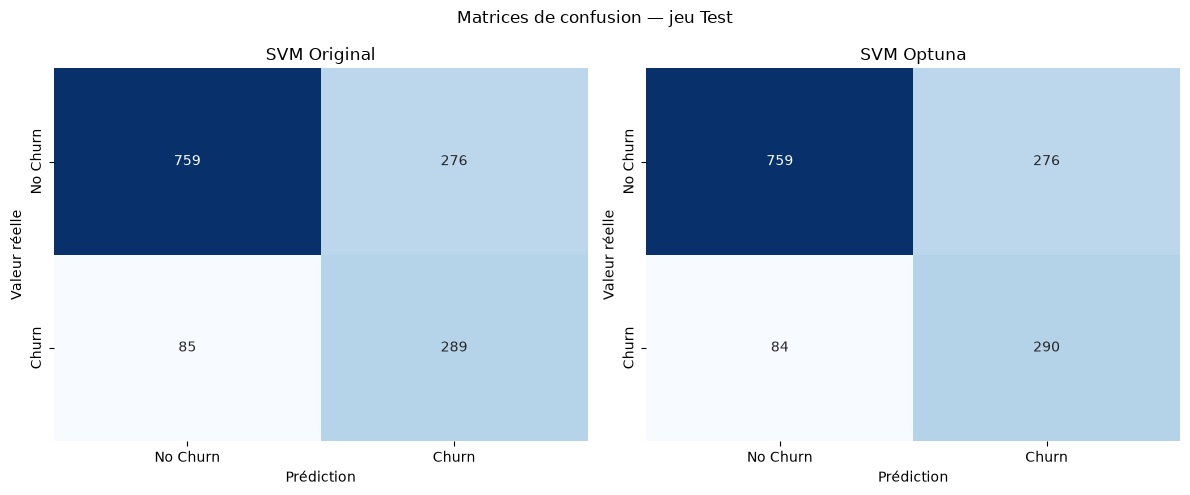

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, y_pred, title in [
    (axes[0], baseline_predictions, "SVM Original"),
    (axes[1], optuna_predictions, "SVM Optuna"),
]:
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["No Churn", "Churn"],
        yticklabels=["No Churn", "Churn"],
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Valeur réelle")

plt.suptitle("Matrices de confusion — jeu Test")
plt.tight_layout()
confusion_matrix_path = REPORTS_DIR / "mlflow_confusion_matrices.png"
plt.savefig(confusion_matrix_path, dpi=150, bbox_inches="tight")
plt.show()

### Courbes ROC

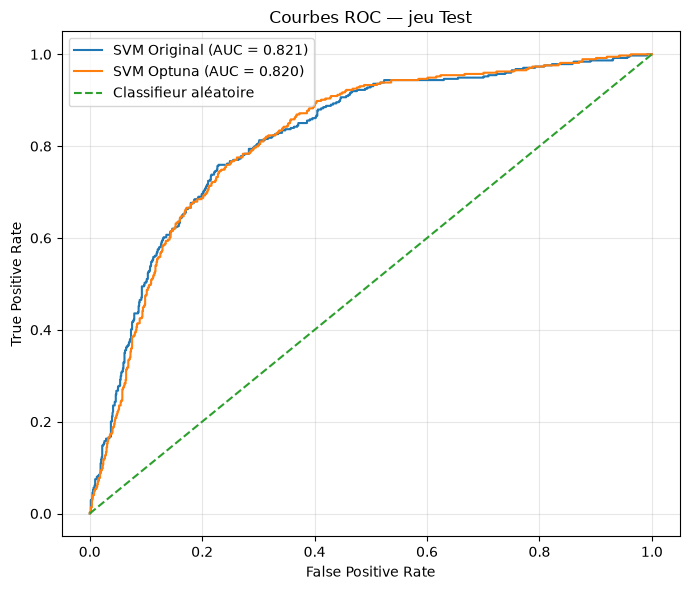

In [45]:
baseline_fpr, baseline_tpr, _ = roc_curve(y_test, baseline_scores, pos_label=POSITIVE_LABEL)
optuna_fpr, optuna_tpr, _ = roc_curve(y_test, optuna_scores, pos_label=POSITIVE_LABEL)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(
    baseline_fpr, baseline_tpr,
    label=f"SVM Original (AUC = {baseline_test_results['ROC-AUC']:.3f})",
)
ax.plot(
    optuna_fpr, optuna_tpr,
    label=f"SVM Optuna (AUC = {optuna_test_results['ROC-AUC']:.3f})",
)
ax.plot([0, 1], [0, 1], linestyle="--", label="Classifieur aléatoire")
ax.set_title("Courbes ROC — jeu Test")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
roc_curve_path = REPORTS_DIR / "mlflow_roc_curves.png"
plt.savefig(roc_curve_path, dpi=150, bbox_inches="tight")
plt.show()

### Courbes Precision–Recall

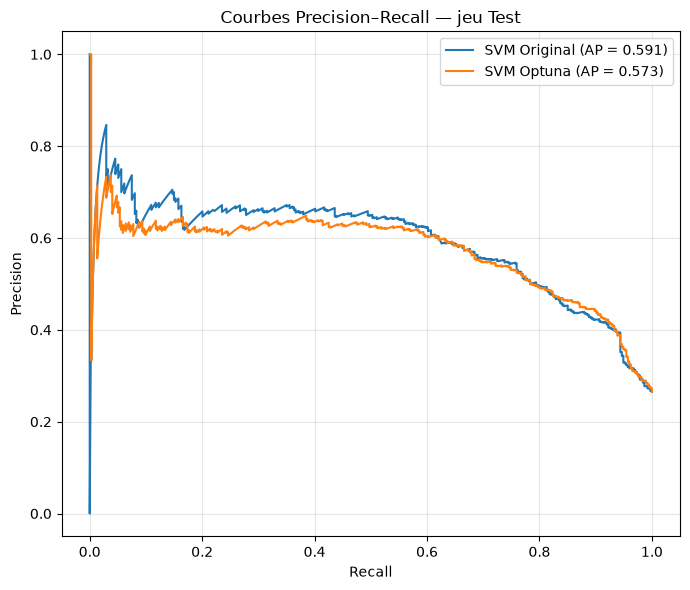

In [46]:
baseline_precision, baseline_recall, _ = precision_recall_curve(
    y_test, baseline_scores, pos_label=POSITIVE_LABEL
)
optuna_precision, optuna_recall, _ = precision_recall_curve(
    y_test, optuna_scores, pos_label=POSITIVE_LABEL
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(
    baseline_recall, baseline_precision,
    label=f"SVM Original (AP = {baseline_test_results['Average Precision']:.3f})",
)
ax.plot(
    optuna_recall, optuna_precision,
    label=f"SVM Optuna (AP = {optuna_test_results['Average Precision']:.3f})",
)
ax.set_title("Courbes Precision–Recall — jeu Test")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
pr_curve_path = REPORTS_DIR / "mlflow_precision_recall_curves.png"
plt.savefig(pr_curve_path, dpi=150, bbox_inches="tight")
plt.show()

## 10. Runs MLflow finaux : SVM Original et SVM Optuna

Deux runs distincts sont créés. Chacun contient :
- les paramètres du modèle ;
- le F1 CV calculé sur Train ;
- toutes les métriques finales calculées sur Test ;
- le modèle entraîné ;
- le rapport de classification et les graphiques utiles.

Les essais Optuna restent disponibles séparément comme runs enfants du run `SVM_Optuna_Study`.

In [47]:
# Écrire les rapports de classification sur disque avant de les journaliser.
baseline_report_path = REPORTS_DIR / "classification_report_svm_original.json"
optuna_report_path = REPORTS_DIR / "classification_report_svm_optuna.json"

with open(baseline_report_path, "w", encoding="utf-8") as file:
    json.dump(baseline_classification_report, file, ensure_ascii=False, indent=4)

with open(optuna_report_path, "w", encoding="utf-8") as file:
    json.dump(optuna_classification_report, file, ensure_ascii=False, indent=4)


def log_final_model_run(
    run_name,
    model,
    model_label,
    cv_f1_mean,
    cv_f1_std,
    test_metrics,
    report_path,
):
    """Crée un run MLflow final et journalise modèle, paramètres, métriques et artefacts."""
    with mlflow.start_run(run_name=run_name) as run:
        mlflow.set_tags({
            "stage": "final_model_evaluation",
            "model_family": "SVM",
            "model_label": model_label,
            "dataset": "Telco Customer Churn",
        })

        model_params = model.get_params(deep=False)
        params_to_log = {
            f"model_{key}": str(value)
            for key, value in model_params.items()
        }
        params_to_log.update({
            "cv_strategy": "StratifiedKFold",
            "cv_n_splits": N_SPLITS,
            "random_state": RANDOM_STATE,
        })
        mlflow.log_params(params_to_log)

        metrics_to_log = {
            "cv_f1_mean": float(cv_f1_mean),
            "cv_f1_std": float(cv_f1_std),
        }
        metrics_to_log.update({
            f"test_{key.lower().replace('-', '_').replace(' ', '_')}": float(value)
            for key, value in test_metrics.items()
            if key != "Model"
        })
        mlflow.log_metrics(metrics_to_log)

        mlflow.sklearn.log_model(
            sk_model=model,
            artifact_path="model",
        )

        mlflow.log_artifact(str(report_path), artifact_path="reports")
        for artifact_path in [
            confusion_matrix_path,
            roc_curve_path,
            pr_curve_path,
        ]:
            mlflow.log_artifact(str(artifact_path), artifact_path="figures")

        return run.info.run_id


baseline_run_id = log_final_model_run(
    run_name="SVM_Original_Baseline",
    model=baseline_model,
    model_label="SVM Original",
    cv_f1_mean=baseline_cv_f1,
    cv_f1_std=baseline_cv_std,
    test_metrics=baseline_test_results,
    report_path=baseline_report_path,
)

optuna_run_id = log_final_model_run(
    run_name="SVM_Optuna_Final",
    model=optuna_model,
    model_label="SVM Optuna",
    cv_f1_mean=float(study.best_value),
    cv_f1_std=float(study.best_trial.user_attrs.get("f1_cv_std", np.nan)),
    test_metrics=optuna_test_results,
    report_path=optuna_report_path,
)

FINAL_RUN_IDS = {
    "SVM Original": baseline_run_id,
    "SVM Optuna": optuna_run_id,
}

print("Runs finaux MLflow créés :")
print(FINAL_RUN_IDS)

2026/11/14 13:09:40 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/14 13:09:53 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Runs finaux MLflow créés :
{'SVM Original': '60287f497cad411383f423084e974e88', 'SVM Optuna': '29509aa9a6ca4361b9fa56bfda5474e5'}


## 11. Sélection du candidat et Model Registry

Pour éviter de sélectionner un modèle sur le jeu de test, le candidat enregistré est déterminé par le **F1 CV sur Train** :
- baseline : moyenne des 3 folds ;
- Optuna : meilleur F1 moyen des 3 folds.

Les métriques Test restent un contrôle final indépendant. Le nom du modèle enregistré est `TelcoChurnClassifier`. Le backend SQLite configuré plus haut est compatible avec le Model Registry.

In [48]:
# Sélection fondée exclusivement sur la validation croisée Train.
if float(study.best_value) > baseline_cv_f1:
    selected_model = optuna_model
    selected_model_label = "SVM Optuna"
    selected_run_id = optuna_run_id
    selected_cv_f1 = float(study.best_value)
else:
    selected_model = baseline_model
    selected_model_label = "SVM Original"
    selected_run_id = baseline_run_id
    selected_cv_f1 = baseline_cv_f1

selected_model_uri = f"runs:/{selected_run_id}/model"

print("Candidat retenu selon le F1 CV :", selected_model_label)
print("F1 CV du candidat :", round(selected_cv_f1, 5))
print("Run source :", selected_run_id)
print("Model URI :", selected_model_uri)

Candidat retenu selon le F1 CV : SVM Original
F1 CV du candidat : 0.62133
Run source : 60287f497cad411383f423084e974e88
Model URI : runs:/60287f497cad411383f423084e974e88/model


In [49]:
registry_result = {
    "registered": False,
    "name": REGISTRY_MODEL_NAME,
    "version": None,
    "source_run_id": selected_run_id,
    "selected_model": selected_model_label,
    "error": None,
}

try:
    registered_model = mlflow.register_model(
        model_uri=selected_model_uri,
        name=REGISTRY_MODEL_NAME,
    )
    registry_result.update({
        "registered": True,
        "version": str(registered_model.version),
    })
    print(
        f"Modèle enregistré : {registered_model.name}, "
        f"version {registered_model.version}"
    )
except Exception as exc:
    registry_result["error"] = f"{type(exc).__name__}: {exc}"
    print("Échec de l'enregistrement dans le Model Registry.")
    print(registry_result["error"])
    print(
        "Vérifiez que MLflow utilise bien le backend SQLite indiqué dans "
        "TRACKING_URI et que la base mlflow.db est accessible."
    )

Registered model 'TelcoChurnClassifier' already exists. Creating a new version of this model...
2026/11/14 13:10:04 WARNING mlflow.tracking._model_registry.fluent: Run with id 60287f497cad411383f423084e974e88 has no artifacts at artifact path 'model', registering model based on models:/m-769a93e1afab4e63a2f009644e5d237f instead


Modèle enregistré : TelcoChurnClassifier, version 2


Created version '2' of model 'TelcoChurnClassifier'.


## 12. Sauvegarde consolidée des résultats

Fichiers attendus :
```text
models/
    svm_optuna_model.joblib

reports/
    optuna_trials.csv
    optuna_best_params.json
    mlflow_model_comparison.csv
    mlflow_evaluation_report.json
```

Les modèles SVM d'origine et les fichiers des notebooks précédents ne sont pas remplacés.

In [50]:
evaluation_report = {
    "project": "Telco Customer Churn — AutoML & MLOps",
    "experiment_name": EXPERIMENT_NAME,
    "experiment_id": str(experiment_id),
    "tracking_uri": TRACKING_URI,
    "dataset": {
        "X_train_shape": list(X_train.shape),
        "X_test_shape": list(X_test.shape),
        "positive_label": POSITIVE_LABEL,
    },
    "optimization": {
        "method": "Optuna TPE",
        "n_trials": N_TRIALS,
        "cv_strategy": "StratifiedKFold",
        "cv_n_splits": N_SPLITS,
        "objective": "F1-score",
        "best_trial": int(study.best_trial.number),
        "best_cv_f1": float(study.best_value),
        "best_params": best_params_for_json,
        "parent_run_id": OPTUNA_STUDY_RUN_ID,
    },
    "cross_validation": {
        "baseline_f1_mean": float(baseline_cv_f1),
        "baseline_f1_std": float(baseline_cv_std),
        "optuna_f1_mean": float(study.best_value),
        "optuna_f1_std": float(study.best_trial.user_attrs.get("f1_cv_std", np.nan)),
    },
    "test_metrics": {
        "svm_original": {
            key: float(value) for key, value in baseline_test_results.items()
            if key != "Model"
        },
        "svm_optuna": {
            key: float(value) for key, value in optuna_test_results.items()
            if key != "Model"
        },
    },
    "mlflow_runs": FINAL_RUN_IDS,
    "registry": registry_result,
    "selected_by_cv_f1": selected_model_label,
}

evaluation_report_path = REPORTS_DIR / "mlflow_evaluation_report.json"
with open(evaluation_report_path, "w", encoding="utf-8") as file:
    json.dump(
        evaluation_report,
        file,
        ensure_ascii=False,
        indent=4,
        allow_nan=False,
    )

# Ajouter les principaux rapports au run d'étude pour faciliter leur consultation.
with mlflow.start_run(run_id=OPTUNA_STUDY_RUN_ID):
    for artifact in [
        trials_path,
        best_params_path,
        comparison_path,
        evaluation_report_path,
        optuna_history_path,
    ]:
        mlflow.log_artifact(str(artifact), artifact_path="reports")

print("Rapport consolidé :", evaluation_report_path)
print("Modèle Optuna      :", OPTUNA_MODEL_PATH)

Rapport consolidé : C:\Users\Octinz\Documents\automl-mlops-platform\reports\mlflow_evaluation_report.json
Modèle Optuna      : C:\Users\Octinz\Documents\automl-mlops-platform\models\svm_optuna_model.joblib


## 13. Interprétation automatique des résultats

Le choix du candidat dans le Model Registry repose sur le F1 CV (Train). Pour l'usage métier, les métriques Test apportent une lecture complémentaire :
- **Recall élevé** : détecter une plus grande part des clients qui vont résilier ;
- **Precision élevée** : réduire les fausses alertes parmi les clients ciblés ;
- **F1-score élevé** : compromis entre Precision et Recall ;
- **ROC-AUC / Average Precision** : capacité à classer les clients selon leur risque.

In [51]:
print("=== SYNTHÈSE DES RÉSULTATS TEST ===")
for metric in ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC", "Average Precision"]:
    base_value = baseline_test_results[metric]
    opt_value = optuna_test_results[metric]
    delta = opt_value - base_value
    better = "Optuna" if delta > 0 else ("Original" if delta < 0 else "Égalité")
    print(
        f"{metric:20s} | Original={base_value:.4f} | "
        f"Optuna={opt_value:.4f} | Écart={delta:+.4f} | Avantage={better}"
    )

print("\nCandidat enregistré selon le F1 CV :", selected_model_label)

if optuna_test_results["F1-score"] > baseline_test_results["F1-score"]:
    print(
        "Sur le jeu Test, SVM Optuna obtient un F1-score supérieur au baseline. "
        "Vérifiez aussi Precision et Recall avant de valider ce choix métier."
    )
elif optuna_test_results["F1-score"] < baseline_test_results["F1-score"]:
    print(
        "Sur le jeu Test, le SVM Original conserve le meilleur F1-score. "
        "Le SVM Optuna reste un candidat à comparer selon le Recall et les métriques de ranking."
    )
else:
    print(
        "Les deux modèles ont le même F1-score sur Test. "
        "La décision doit tenir compte du coût métier des faux positifs et faux négatifs."
    )

=== SYNTHÈSE DES RÉSULTATS TEST ===
Accuracy             | Original=0.7438 | Optuna=0.7445 | Écart=+0.0007 | Avantage=Optuna
Precision            | Original=0.5115 | Optuna=0.5124 | Écart=+0.0009 | Avantage=Optuna
Recall               | Original=0.7727 | Optuna=0.7754 | Écart=+0.0027 | Avantage=Optuna
F1-score             | Original=0.6155 | Optuna=0.6170 | Écart=+0.0015 | Avantage=Optuna
ROC-AUC              | Original=0.8210 | Optuna=0.8198 | Écart=-0.0012 | Avantage=Original
Average Precision    | Original=0.5914 | Optuna=0.5729 | Écart=-0.0185 | Avantage=Original

Candidat enregistré selon le F1 CV : SVM Original
Sur le jeu Test, SVM Optuna obtient un F1-score supérieur au baseline. Vérifiez aussi Precision et Recall avant de valider ce choix métier.


## 14. Conclusion

Cette étape ajoute deux briques au pipeline AutoML & MLOps :

1. **Optuna** automatise la recherche d'hyperparamètres du SVM avec une stratégie TPE et une validation croisée stratifiée. Il propose une configuration en maximisant le F1-score sur les données Train.
2. **MLflow Tracking** conserve les paramètres, métriques, runs, modèles et artefacts. Chaque trial Optuna est un run enfant ; les SVM Original et SVM Optuna disposent chacun d'un run final distinct.
3. **MLflow Model Registry** permet de nommer et versionner le candidat retenu sous `TelcoChurnClassifier`. La sélection est basée sur le F1 CV, sans utiliser le jeu Test.
4. **Reproductibilité** : les paramètres Optuna, les scores, le tableau comparatif et le rapport final sont sauvegardés dans `reports/`, tandis que le nouveau modèle est stocké sous `models/svm_optuna_model.joblib`.

Le SVM Optuna n'est pas automatiquement considéré comme meilleur : les résultats Test et les besoins métier (détection maximale du churn ou limitation des fausses alertes) doivent guider la validation finale.

### Fichiers produits
- `models/svm_optuna_model.joblib`
- `reports/optuna_trials.csv`
- `reports/optuna_best_params.json`
- `reports/mlflow_model_comparison.csv`
- `reports/mlflow_evaluation_report.json`
- Plusieurs graphiques PNG d'évaluation
- `mlflow.db` et `mlartifacts/` pour le tracking local

### Consulter l'interface MLflow
Depuis PowerShell, à la racine du projet, exécutez :
```powershell
mlflow ui --backend-store-uri "sqlite:///C:/Users/Octinz/Documents/automl-mlops-platform/mlflow.db" --host 127.0.0.1 --port 5000
```
Puis ouvrez `http://127.0.0.1:5000` dans le navigateur.

Remplacez le chemin de la base dans la commande uniquement si le projet est placé dans un autre dossier.